# DWD-Wetterdaten Berlin 2025: Explorative Datenanalyse

Dieses Notebook untersucht tägliche Temperatur-, Niederschlags- und Sonnenscheindaten der DWD-Station **Berlin-Tempelhof (00433)** für das Kalenderjahr 2025. Die Rohdaten werden aus dem frei zugänglichen DWD-CDC-Archiv bezogen und die Ergebnisse ausschließlich aus den tatsächlich geladenen Messwerten berechnet.

## Im Browser öffnen

Im VS-Code-Terminal im Projektordner `jupyter lab --no-browser --ip=0.0.0.0 --port=8888` ausführen und den angezeigten Token-Link im Browser öffnen. In einer Dev-Container-Umgebung den Port 8888 gegebenenfalls über die VS-Code-Ports-Ansicht weiterleiten. Anschließend die Zellen der Reihe nach ausführen oder **Restart & Run All** verwenden.

Die Datei lässt sich in Jupyter über **File → Save Notebook** als `.ipynb` speichern und über **File → Save and Export Notebook As** z. B. als HTML exportieren.

## 1. Benötigte Bibliotheken

Verwendet werden `pandas`, `numpy` und `matplotlib` für Datenaufbereitung und Grafiken sowie Python-Standardbibliotheken für HTTP-Abruf und ZIP-Dateien.

In [1]:
from pathlib import Path
from urllib.request import urlopen
from urllib.error import URLError, HTTPError
from html.parser import HTMLParser
from zipfile import ZipFile
from io import BytesIO
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
plt.style.use("seaborn-v0_8-whitegrid")

STATION_ID = "00433"
STATION_NAME = "Berlin-Tempelhof"
YEAR = 2025
BASE_URL = "https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl"
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)


## Datenquelle und Messgrößen

Quelle ist der DWD Climate Data Center (CDC), tägliche Stationsmessungen (`kl`). Für die gesamte Stationshistorie und die jeweils aktuellen Daten werden passende ZIP-Archive aus den DWD-Verzeichnissen geladen und anhand des Datums zusammengeführt. Lokale ZIP-Dateien bleiben im Ordner `data/` erhalten.

Untersucht werden `TMK` (Tagesmittel), `TXK` (Tagesmaximum), `TNK` (Tagesminimum) in °C, `RSK` (Tagessumme Niederschlag) in mm und `SDK` (Sonnenscheindauer) in Stunden. Der Wert `-999` gilt beim DWD als fehlend. Die Messung an einer Station ist nicht repräsentativ für jeden Berliner Stadtteil.

In [6]:
class DWDLinkParser(HTMLParser):
    def __init__(self):
        super().__init__()
        self.links = []

    def handle_starttag(self, tag, attrs):
        if tag == "a":
            href = dict(attrs).get("href")
            if href:
                self.links.append(href)


def load_station_archives():
    """Lädt verfügbare historische und aktuelle Stationsarchive aus dem DWD-CDC."""
    frames = []
    archive_names = []

    for period in ("historical", "recent"):
        folder_url = f"{BASE_URL}/{period}/"
        try:
            with urlopen(folder_url, timeout=30) as response:
                parser = DWDLinkParser()
                parser.feed(response.read().decode("utf-8", errors="replace"))
        except (HTTPError, URLError, TimeoutError) as exc:
            print(f"DWD-Verzeichnis {period!r} nicht erreichbar: {exc}")
            continue

        candidates = sorted({
            link for link in parser.links
            if link.startswith(f"tageswerte_KL_{STATION_ID}_") and link.endswith(".zip")
        })
        for archive_name in candidates:
            archive_path = DATA_DIR / archive_name
            if not archive_path.exists():
                archive_url = f"{folder_url}{archive_name}"
                try:
                    with urlopen(archive_url, timeout=60) as response:
                        archive_path.write_bytes(response.read())
                except (HTTPError, URLError, TimeoutError) as exc:
                    print(f"Archiv {archive_name} konnte nicht geladen werden: {exc}")
                    continue

            try:
                with ZipFile(archive_path) as archive:
                    text_files = [
                        name for name in archive.namelist()
                        if name.lower().startswith("produkt_klima_tag_") and name.lower().endswith(".txt")
                    ]
                    for text_name in text_files:
                        with archive.open(text_name) as file:
                            frame = pd.read_csv(
                                file,
                                sep=";",
                                encoding="latin-1",
                                na_values=[-999, "-999", ""],
                                low_memory=False,
                            )
                        frame = frame.drop(columns=["eor"], errors="ignore")
                        frames.append(frame)
                        archive_names.append(archive_name)
            except (OSError, ValueError, KeyError) as exc:
                print(f"Archiv {archive_name} ist nicht lesbar: {exc}")

    if not frames:
        raise RuntimeError(
            "Keine Stationsdaten erhalten. Bitte Netzwerkverbindung und DWD-Open-Data-URL prüfen. "
            "Die Quelle ist https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl/"
        )

    data = pd.concat(frames, ignore_index=True)
    data.columns = data.columns.str.strip()
    data = data.drop_duplicates(subset="MESS_DATUM", keep="last")
    data["MESS_DATUM"] = pd.to_datetime(data["MESS_DATUM"].astype(str), format="%Y%m%d", errors="coerce")
    data = data.dropna(subset=["MESS_DATUM"]).sort_values("MESS_DATUM").set_index("MESS_DATUM")

    for column in ("TMK", "TXK", "TNK", "RSK", "SDK"):
        if column in data:
            data[column] = pd.to_numeric(data[column], errors="coerce")

    return data, sorted(set(archive_names))


try:
    station_data, used_archives = load_station_archives()
except Exception as error:
    raise RuntimeError(f"DWD-Datenabruf fehlgeschlagen: {error}") from error

print(f"Station: {STATION_NAME} ({STATION_ID})")
print(f"Rohdaten: {len(station_data):,} Tage, {station_data.index.min().date()} bis {station_data.index.max().date()}")
print("Verwendete Archive:", ", ".join(used_archives))
display(station_data.tail())

Station: Berlin-Tempelhof (00433)
Rohdaten: 28,795 Tage, 1948-01-01 bis 2026-11-01
Verwendete Archive: tageswerte_KL_00433_19480101_20251231_hist.zip, tageswerte_KL_00433_akt.zip


,STATIONS_ID,QN_3,FX,FM,QN_4,RSK,RSKF,SDK,SHK_TAG,NM,VPM,PM,TMK,UPM,TXK,TNK,TGK
MESS_DATUM,,,,,,,,,,,,,,,,,
2026-10-28,433,1.0,7.6,2.7,1,0.7,6.0,NaN,0.0,5.7,10.7,1017.76,9.2,91.83,12.5,3.6,1.0
2026-10-29,433,1.0,6.2,1.8,1,0.0,6.0,NaN,0.0,4.6,10.4,1023.85,8.5,93.46,12.6,3.6,-0.4
2026-10-30,433,1.0,6.1,2.2,1,0.0,6.0,NaN,0.0,8.0,10.6,1026.08,8.2,97.13,9.5,6.7,7.4
2026-10-31,433,1.0,8.2,3.7,1,0.0,6.0,NaN,0.0,6.8,10.1,1025.31,9.2,86.42,11.7,5.6,3.1
2026-11-01,433,1.0,5.5,2.1,1,0.0,0.0,NaN,0.0,7.9,9.0,1026.20,8.3,82.21,10.7,6.8,5.4


## Datenqualität und Jahreskennzahlen

Der Sollumfang beträgt 365 Kalendertage. Neben tatsächlich fehlenden Datumseinträgen wird je Messgröße die Anzahl vorhandener Werte ausgewiesen. Regen- und Sonnenscheinsummen berücksichtigen nur beobachtete Tage; ihre Abdeckung steht deshalb direkt daneben.

In [7]:
expected_dates = pd.date_range(f"{YEAR}-01-01", f"{YEAR}-12-31", freq="D")
year_data = station_data.loc[f"{YEAR}-01-01":f"{YEAR}-12-31"].reindex(expected_dates)
year_data.index.name = "Datum"

variables = {
    "TMK": "Tagesmitteltemperatur (°C)",
    "TXK": "Tagesmaximum (°C)",
    "TNK": "Tagesminimum (°C)",
    "RSK": "Niederschlag (mm)",
    "SDK": "Sonnenschein (h)",
}
missing_columns = [column for column in variables if column not in year_data.columns]
if missing_columns:
    raise KeyError(f"Diese erwarteten DWD-Spalten fehlen: {missing_columns}")

missing_dates = expected_dates.difference(station_data.index)
coverage_rows = []
for column, label in variables.items():
    observed = int(year_data[column].notna().sum())
    coverage_rows.append({
        "Messgröße": label,
        "Messwerte": f"{observed}/{len(expected_dates)}",
        "Abdeckung (%)": round(100 * observed / len(expected_dates), 1),
        "Fehlend": len(expected_dates) - observed,
    })

print(f"Kalenderjahr {YEAR}: {len(year_data)} Solltage")
print(f"Fehlende Datumszeilen: {len(missing_dates)}")
if len(missing_dates):
    print("Fehlende Tage:", ", ".join(date.strftime("%d.%m.%Y") for date in missing_dates))
display(pd.DataFrame(coverage_rows).set_index("Messgröße"))

def value_on_extreme(series, kind):
    valid = series.dropna()
    if valid.empty:
        return "keine Daten"
    date = valid.idxmax() if kind == "max" else valid.idxmin()
    return f"{valid.loc[date]:.1f} °C am {date:%d.%m.%Y}"

rain = year_data["RSK"]
sunshine = year_data["SDK"]
annual_metrics = pd.DataFrame({
    "Kennzahl": [
        "Jahresmittel Tagesmitteltemperatur",
        "Höchstes Tagesmaximum",
        "Niedrigstes Tagesminimum",
        "Niederschlagssumme",
        "Regentage (mindestens 1 mm)",
        "Stärkster Tagesniederschlag",
        "Sonnenscheinsumme",
    ],
    "Wert": [
        f"{year_data['TMK'].mean():.1f} °C" if year_data["TMK"].notna().any() else "keine Daten",
        value_on_extreme(year_data["TXK"], "max"),
        value_on_extreme(year_data["TNK"], "min"),
        f"{rain.sum(min_count=1):.1f} mm" if rain.notna().any() else "keine Daten",
        f"{int((rain >= 1).sum())} Tage" if rain.notna().any() else "keine Daten",
        f"{rain.max():.1f} mm am {rain.idxmax():%d.%m.%Y}" if rain.notna().any() else "keine Daten",
        f"{sunshine.sum(min_count=1):.1f} h" if sunshine.notna().any() else "keine Daten",
    ],
})
display(annual_metrics.set_index("Kennzahl"))

monthly = year_data.resample("MS").agg({"TMK": "mean", "TNK": "min", "TXK": "max", "RSK": lambda values: values.sum(min_count=1), "SDK": lambda values: values.sum(min_count=1)})
monthly.index = monthly.index.month
monthly.index.name = "Monat"
monthly

Kalenderjahr 2025: 365 Solltage
Fehlende Datumszeilen: 0


,Messwerte,Abdeckung (%),Fehlend
Messgröße,,,
Tagesmitteltemperatur (°C),365/365,100.0,0
Tagesmaximum (°C),365/365,100.0,0
Tagesminimum (°C),365/365,100.0,0
Niederschlag (mm),365/365,100.0,0
Sonnenschein (h),0/365,0.0,365


,Wert
Kennzahl,
Jahresmittel Tagesmitteltemperatur,11.1 °C
Höchstes Tagesmaximum,37.6 °C am 02.07.2025
Niedrigstes Tagesminimum,-11.6 °C am 18.02.2025
Niederschlagssumme,458.5 mm
Regentage (mindestens 1 mm),97 Tage
Stärkster Tagesniederschlag,24.7 mm am 12.07.2025
Sonnenscheinsumme,keine Daten


,TMK,TNK,TXK,RSK,SDK
Monat,,,,,
1,3.074194,-4.7,14.6,54.9,NaN
2,1.703571,-11.6,15.4,16.0,NaN
3,7.106452,-4.5,19.1,8.7,NaN
4,12.166667,-0.8,26.7,13.7,NaN
5,13.793548,0.9,29.0,33.8,NaN
6,19.726667,9.4,34.7,34.6,NaN
7,19.819355,12.7,37.6,127.4,NaN
8,19.135484,8.9,34.5,32.6,NaN
9,16.193333,4.7,29.5,35.1,NaN


## Korrelationen der fünf Wettermerkmale

Für 2025 werden Tagesmittel-, Höchst- und Tiefsttemperatur, Niederschlag sowie maximale Windböe untersucht. Sonnenschein ist nicht enthalten, da die DWD-Reihe für diese Station 2025 keine gültigen SDK-Werte enthält. Berechnet wird Pearson-$r$ auf paarweise vollständigen Tageswerten; die Fallzahlen stehen separat dabei. Bei Niederschlag sind viele Nullwerte und einzelne Starkregenereignisse zu beachten, daher ist die Korrelation nur ein Hinweis auf lineare Zusammenhänge und keine Ursache-Wirkungs-Aussage.

Pearson-Korrelationen (paarweise vollständige Tageswerte):


,Tagesmitteltemperatur (°C),Tagesmaximum (°C),Tagesminimum (°C),Niederschlag (mm),Maximale Windböe (m/s)
Tagesmitteltemperatur (°C),1.00,0.98,0.95,0.11,0.24
Tagesmaximum (°C),0.98,1.00,0.87,0.04,0.22
Tagesminimum (°C),0.95,0.87,1.00,0.21,0.28
Niederschlag (mm),0.11,0.04,0.21,1.00,0.16
Maximale Windböe (m/s),0.24,0.22,0.28,0.16,1.00


Anzahl verwendeter Tagespaare:


,Tagesmitteltemperatur (°C),Tagesmaximum (°C),Tagesminimum (°C),Niederschlag (mm),Maximale Windböe (m/s)
Tagesmitteltemperatur (°C),365,365,365,365,365
Tagesmaximum (°C),365,365,365,365,365
Tagesminimum (°C),365,365,365,365,365
Niederschlag (mm),365,365,365,365,365
Maximale Windböe (m/s),365,365,365,365,365


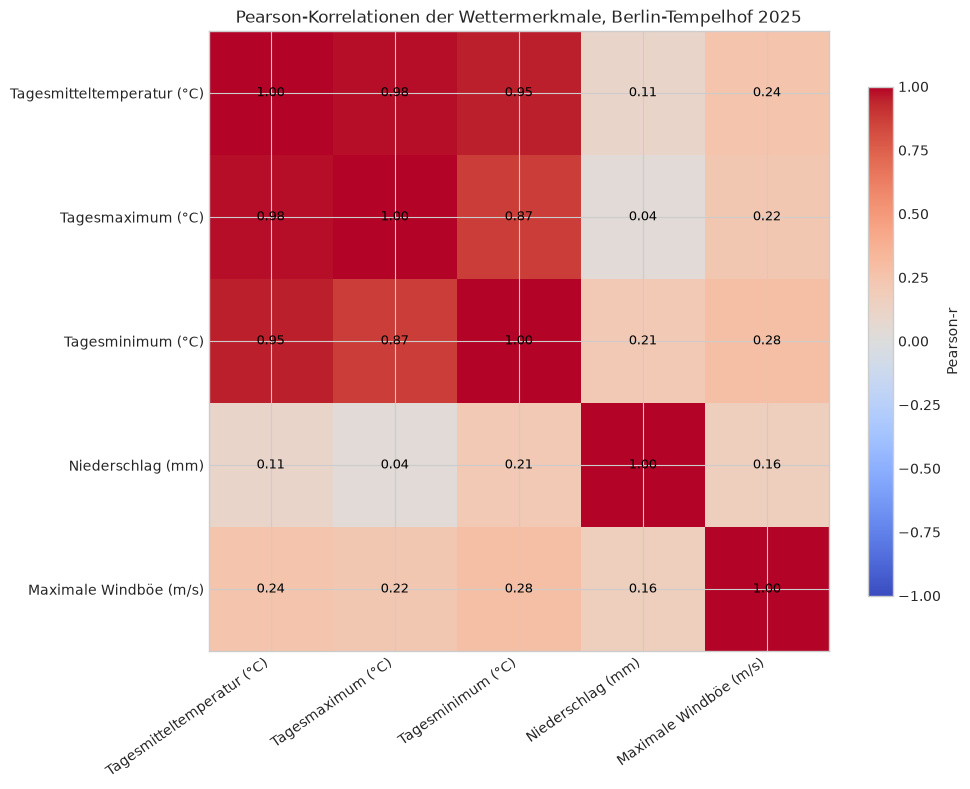

## Auswertung der Korrelationen

- **Tagesmitteltemperatur (°C) ↔ Tagesmaximum (°C):** starker positiver Zusammenhang ($r=0.98$, $n=365$ Tagespaare).
- **Tagesmitteltemperatur (°C) ↔ Tagesminimum (°C):** starker positiver Zusammenhang ($r=0.95$, $n=365$ Tagespaare).
- **Tagesmaximum (°C) ↔ Tagesminimum (°C):** starker positiver Zusammenhang ($r=0.87$, $n=365$ Tagespaare).
- **Tagesminimum (°C) ↔ Maximale Windböe (m/s):** schwacher positiver Zusammenhang ($r=0.28$, $n=365$ Tagespaare).
- **Tagesmitteltemperatur (°C) ↔ Maximale Windböe (m/s):** schwacher positiver Zusammenhang ($r=0.24$, $n=365$ Tagespaare).

Pearson-$r$ beschreibt hier lineare Mitbewegungen der täglichen Stationswerte. Besonders Temperaturmerkmale sind teilweise definitionsgemäß eng verwandt; Niederschlag und Windböen können durch einzelne Ereignisse geprägt sein. Korrelationen erlauben keine kausalen Schlüsse.

In [14]:
correlation_features = {
    "TMK": "Tagesmitteltemperatur (°C)",
    "TXK": "Tagesmaximum (°C)",
    "TNK": "Tagesminimum (°C)",
    "RSK": "Niederschlag (mm)",
    "FX": "Maximale Windböe (m/s)",
}
missing_correlation_features = [name for name in correlation_features if name not in year_data.columns]
if missing_correlation_features:
    raise KeyError(f"Für die Korrelationsanalyse fehlen DWD-Spalten: {missing_correlation_features}")

correlation_data = year_data[list(correlation_features)].apply(pd.to_numeric, errors="coerce")
correlation_data = correlation_data.rename(columns=correlation_features)
correlation_matrix = correlation_data.corr(method="pearson", min_periods=30)
pair_counts = correlation_data.notna().astype(int).T.dot(correlation_data.notna().astype(int))

print("Pearson-Korrelationen (paarweise vollständige Tageswerte):")
display(correlation_matrix.round(2))
print("Anzahl verwendeter Tagespaare:")
display(pair_counts)

fig, ax = plt.subplots(figsize=(10, 8))
heatmap = ax.imshow(np.ma.masked_invalid(correlation_matrix.to_numpy()), vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(np.arange(len(correlation_matrix.columns)))
ax.set_yticks(np.arange(len(correlation_matrix.index)))
ax.set_xticklabels(correlation_matrix.columns, rotation=35, ha="right")
ax.set_yticklabels(correlation_matrix.index)
ax.set_title(f"Pearson-Korrelationen der Wettermerkmale, Berlin-Tempelhof {YEAR}")
for row in range(len(correlation_matrix.index)):
    for column in range(len(correlation_matrix.columns)):
        value = correlation_matrix.iloc[row, column]
        label = f"{value:.2f}" if pd.notna(value) else "n/a"
        ax.text(column, row, label, ha="center", va="center", color="black", fontsize=9)
colorbar = fig.colorbar(heatmap, ax=ax, shrink=0.82)
colorbar.set_label("Pearson-r")
fig.tight_layout()
plt.show()

pair_results = []
for row in range(len(correlation_matrix.columns)):
    for column in range(row + 1, len(correlation_matrix.columns)):
        value = correlation_matrix.iloc[row, column]
        if pd.notna(value):
            pair_results.append((abs(value), value, correlation_matrix.index[row], correlation_matrix.columns[column], int(pair_counts.iloc[row, column])))

pair_results.sort(reverse=True)
if pair_results:
    def correlation_strength(value):
        magnitude = abs(value)
        if magnitude >= 0.7:
            return "starker"
        if magnitude >= 0.4:
            return "mittlerer"
        if magnitude >= 0.2:
            return "schwacher"
        return "sehr schwacher"

    interpretation_lines = []
    for _, value, first, second, count in pair_results[:5]:
        direction = "positiver" if value > 0 else "negativer"
        interpretation_lines.append(
            f"- **{first} ↔ {second}:** {correlation_strength(value)} {direction} Zusammenhang "
            f"($r={value:.2f}$, $n={count}$ Tagespaare)."
        )
    display(Markdown("## Auswertung der Korrelationen\n\n" + "\n".join(interpretation_lines) + "\n\nPearson-$r$ beschreibt hier lineare Mitbewegungen der täglichen Stationswerte. Besonders Temperaturmerkmale sind teilweise definitionsgemäß eng verwandt; Niederschlag und Windböen können durch einzelne Ereignisse geprägt sein. Korrelationen erlauben keine kausalen Schlüsse."))
else:
    print("Für mindestens 30 gemeinsame Tageswerte je Paar konnten keine Korrelationen berechnet werden.")

## Einordnung gegenüber 1991–2020

Sofern die geladene Stationshistorie die Referenzjahre enthält, werden Monatsmittel der Temperatur und mittlere Monatssummen des Niederschlags mit dem Stationsmittel 1991–2020 verglichen. Das ist eine stationsbezogene Orientierung, keine Aussage über den Klimatrend oder jeden Ort in Berlin.

In [8]:
reference = station_data.loc["1991-01-01":"2020-12-31"]
if reference.empty:
    print("Vergleich nicht möglich: Im geladenen Archiv fehlen Daten für 1991–2020.")
    monthly_comparison = pd.DataFrame()
else:
    temp_by_year_month = reference["TMK"].groupby([reference.index.year, reference.index.month]).mean()
    temp_normal = temp_by_year_month.groupby(level=1).mean()
    temp_years = temp_by_year_month.groupby(level=1).count()

    rain_by_year_month = reference["RSK"].groupby([reference.index.year, reference.index.month]).sum(min_count=1)
    rain_normal = rain_by_year_month.groupby(level=1).mean()
    rain_years = rain_by_year_month.groupby(level=1).count()

    monthly_comparison = pd.DataFrame({
        "TMK 2025 (°C)": monthly["TMK"],
        "TMK-Normal 1991–2020 (°C)": temp_normal,
        "TMK-Abweichung (°C)": monthly["TMK"] - temp_normal,
        "Jahre TMK-Referenz": temp_years,
        "RSK 2025 (mm)": monthly["RSK"],
        "RSK-Normal 1991–2020 (mm)": rain_normal,
        "RSK-Abweichung (mm)": monthly["RSK"] - rain_normal,
        "Jahre RSK-Referenz": rain_years,
    }).reindex(range(1, 13))
    monthly_comparison.index.name = "Monat"
    display(monthly_comparison.round(1))

,TMK 2025 (°C),TMK-Normal 1991–2020 (°C),TMK-Abweichung (°C),Jahre TMK-Referenz,RSK 2025 (mm),RSK-Normal 1991–2020 (mm),RSK-Abweichung (mm),Jahre RSK-Referenz
Monat,,,,,,,,
1,3.1,1.2,1.9,30,54.9,47.7,7.2,30
2,1.7,2.1,-0.4,30,16.0,36.0,-20.0,30
3,7.1,5.2,2.0,30,8.7,40.5,-31.8,30
4,12.2,10.3,1.9,30,13.7,29.3,-15.6,30
5,13.8,14.7,-0.9,30,33.8,51.2,-17.4,30
6,19.7,18.0,1.7,30,34.6,58.5,-23.9,30
7,19.8,20.2,-0.3,30,127.4,71.6,55.7,30
8,19.1,19.7,-0.6,30,32.6,58.1,-25.5,30
9,16.2,15.2,0.9,30,35.1,46.6,-11.5,30


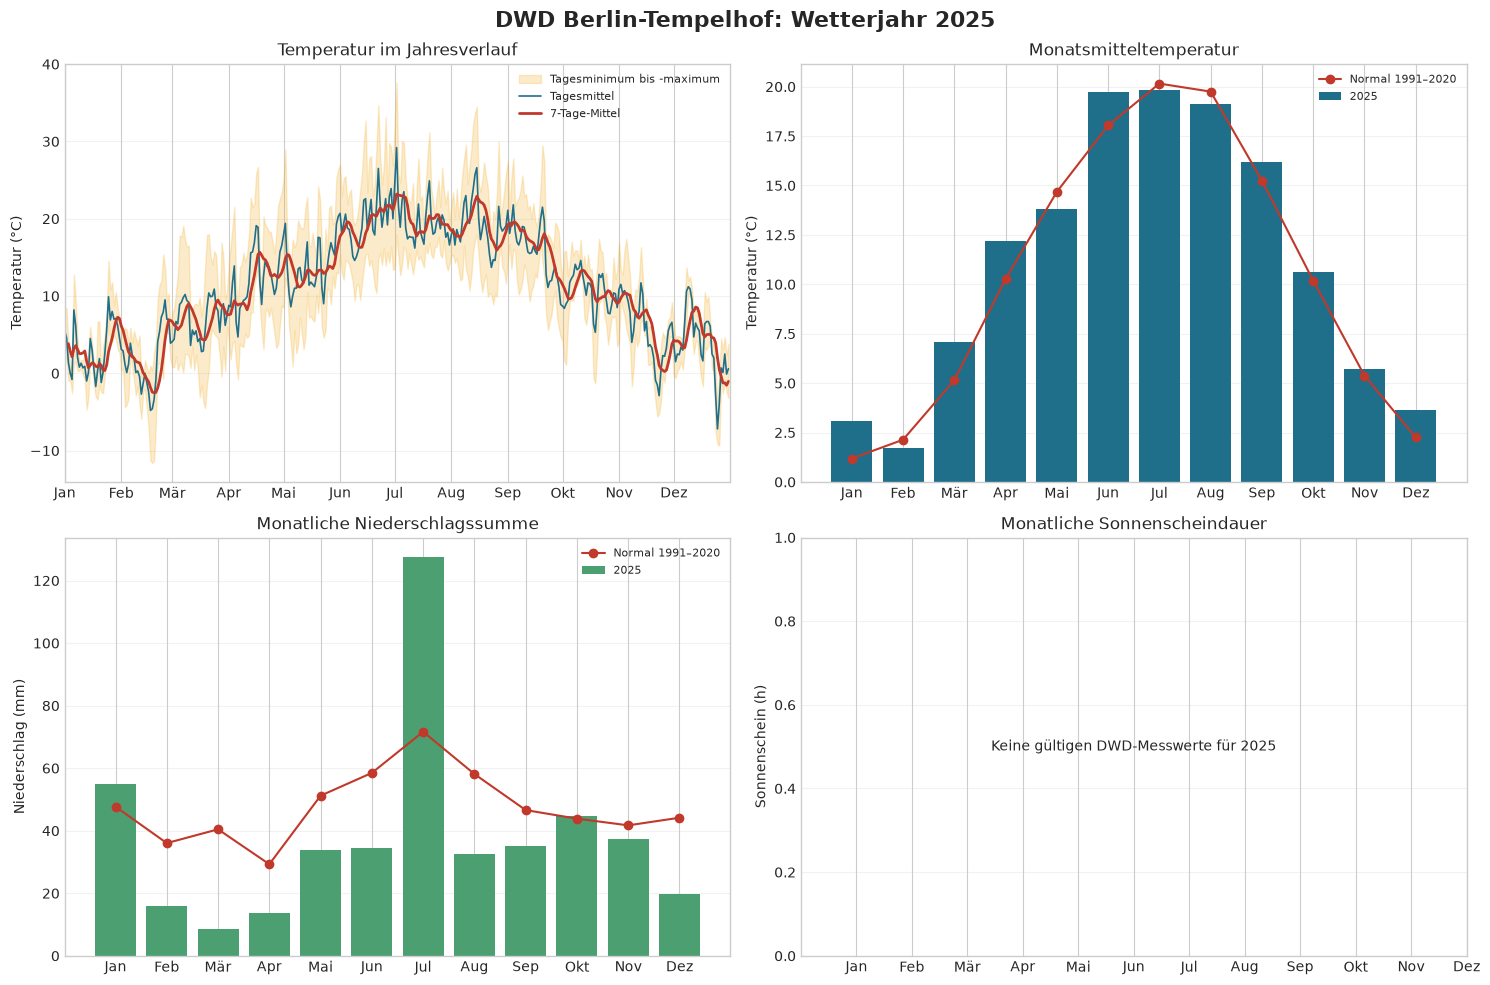

In [11]:
month_labels = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]
months = np.arange(1, 13)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle(f"DWD Berlin-Tempelhof: Wetterjahr {YEAR}", fontsize=16, fontweight="bold")

ax = axes[0, 0]
valid_range = year_data["TNK"].notna() & year_data["TXK"].notna()
ax.fill_between(year_data.index, year_data["TNK"], year_data["TXK"], where=valid_range, color="#f3a712", alpha=0.22, label="Tagesminimum bis -maximum")
ax.plot(year_data.index, year_data["TMK"], color="#1f6f8b", linewidth=1.2, label="Tagesmittel")
ax.plot(year_data.index, year_data["TMK"].rolling(7, min_periods=3).mean(), color="#c0392b", linewidth=2, label="7-Tage-Mittel")
ax.set(title="Temperatur im Jahresverlauf", ylabel="Temperatur (°C)")
ax.set_xlim(pd.Timestamp(f"{YEAR}-01-01"), pd.Timestamp(f"{YEAR + 1}-01-01"))
ax.set_xticks(pd.date_range(f"{YEAR}-01-01", f"{YEAR}-12-01", freq="MS"))
ax.set_xticklabels(month_labels)
ax.legend(frameon=False, fontsize=8)

ax = axes[0, 1]
ax.bar(months, monthly["TMK"], color="#1f6f8b", label="2025")
if not monthly_comparison.empty:
    ax.plot(months, monthly_comparison["TMK-Normal 1991–2020 (°C)"], color="#c0392b", marker="o", label="Normal 1991–2020")
ax.set(title="Monatsmitteltemperatur", ylabel="Temperatur (°C)", xticks=months, xticklabels=month_labels)
ax.legend(frameon=False, fontsize=8)

ax = axes[1, 0]
ax.bar(months, monthly["RSK"], color="#4c9f70", label="2025")
if not monthly_comparison.empty:
    ax.plot(months, monthly_comparison["RSK-Normal 1991–2020 (mm)"], color="#c0392b", marker="o", label="Normal 1991–2020")
ax.set(title="Monatliche Niederschlagssumme", ylabel="Niederschlag (mm)", xticks=months, xticklabels=month_labels)
ax.legend(frameon=False, fontsize=8)

ax = axes[1, 1]
if monthly["SDK"].notna().any():
    ax.bar(months, monthly["SDK"], color="#f3a712")
else:
    ax.text(0.5, 0.5, "Keine gültigen DWD-Messwerte für 2025", ha="center", va="center", wrap=True, transform=ax.transAxes)
    ax.set_ylim(0, 1)
ax.set(title="Monatliche Sonnenscheindauer", ylabel="Sonnenschein (h)", xticks=months, xticklabels=month_labels)

for ax in axes.flat:
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

In [12]:
def month_extreme(series, kind="max", unit=""):
    valid = series.dropna()
    if valid.empty:
        return "keine vollständigen Messwerte"
    month = valid.idxmax() if kind == "max" else valid.idxmin()
    return f"{month_labels[month - 1]} ({valid.loc[month]:.1f}{unit})"

findings = [
    f"**Temperatur:** Jahresmittel {year_data['TMK'].mean():.1f} °C; wärmster Monat {month_extreme(monthly['TMK'], 'max', ' °C')}, kältester Monat {month_extreme(monthly['TMK'], 'min', ' °C')}.",
    f"**Niederschlag:** {rain.sum(min_count=1):.1f} mm im Jahr; niederschlagsreichster Monat {month_extreme(monthly['RSK'], 'max', ' mm')} und {int((rain >= 1).sum())} Tage mit mindestens 1 mm.",
]

if sunshine.notna().any():
    findings.append(
        f"**Sonnenschein:** {sunshine.sum(min_count=1):.1f} Stunden im Jahr; "
        f"sonnenscheinreichster Monat {month_extreme(monthly['SDK'], 'max', ' h')}."
    )
else:
    findings.append("**Sonnenschein:** Für 2025 liegen in der DWD-Datei dieser Station keine gültigen SDK-Messwerte vor.")

if not monthly_comparison.empty and monthly_comparison["TMK-Abweichung (°C)"].notna().any():
    anomaly = monthly_comparison["TMK-Abweichung (°C)"].dropna()
    warmest_deviation = anomaly.idxmax()
    coolest_deviation = anomaly.idxmin()
    findings.append(
        f"**Referenzvergleich:** Größte positive Monatsabweichung beim Temperaturmittel im {month_labels[warmest_deviation - 1]} "
        f"({anomaly.loc[warmest_deviation]:+.1f} °C), größte negative im {month_labels[coolest_deviation - 1]} "
        f"({anomaly.loc[coolest_deviation]:+.1f} °C) gegenüber 1991–2020."
    )

findings.append(f"**Datenabdeckung:** Temperaturmittel an {int(year_data['TMK'].notna().sum())} von {len(expected_dates)} Tagen vorhanden.")
display(Markdown("## Kurzbefunde\n\n" + "\n\n".join(f"- {finding}" for finding in findings)))

## Kurzbefunde

- **Temperatur:** Jahresmittel 11.1 °C; wärmster Monat Jul (19.8 °C), kältester Monat Feb (1.7 °C).

- **Niederschlag:** 458.5 mm im Jahr; niederschlagsreichster Monat Jul (127.4 mm) und 97 Tage mit mindestens 1 mm.

- **Sonnenschein:** Für 2025 liegen in der DWD-Datei dieser Station keine gültigen SDK-Messwerte vor.

- **Referenzvergleich:** Größte positive Monatsabweichung beim Temperaturmittel im Mär (+2.0 °C), größte negative im Mai (-0.9 °C) gegenüber 1991–2020.

- **Datenabdeckung:** Temperaturmittel an 365 von 365 Tagen vorhanden.

## Grenzen der Auswertung und nächste Schritte

- Eine DWD-Station bildet lokale Unterschiede innerhalb Berlins nur eingeschränkt ab.
- Niederschlag und Sonnenschein können stations- und messbedingt fehlende Werte enthalten; die Abdeckung steht oben und fehlende Werte werden nicht als Null interpretiert.
- Der Vergleich 1991–2020 ist eine Monatsreferenz derselben Station. Er ersetzt keine offizielle Gebietsmittel-Auswertung und belegt für sich genommen keinen Klimatrend.
- Das Jahr 2025 wird als einzelnes Jahr beschrieben. Für Aussagen über langfristige Veränderungen sollte die gesamte Stationsreihe analysiert werden.

Die Originalarchive liegen nach dem ersten erfolgreichen Download im Ordner `data/`. Zum erneuten Laden können sie dort gelöscht werden; beim nächsten Durchlauf lädt das Notebook die DWD-Dateien erneut.